## Журнал исправлений

Исправлены только явные ошибки, в которых нет сомнений. Каждое место в ноутбуке помечено **⚠ ИСПРАВЛЕНИЕ №…**: что было, что стало и почему. Остальной текст и код не менялись.

| № | Где | Что исправлено | Меняет расчёт k |
|---|---|---|---|
| 1 | «5. Примеры заводов», Chambal | Перевод Гкал → MMBtu: 22,6 → 24,9 | нет |

Код не менялся, поэтому ноутбук не перезапускался: выводы ячеек — исходные.


# Химия и физика производства карбамида для экономической модели

Этот ноутбук собирает физическую базу под нашу экономическую модель. Все данные взяты из официального справочника по наилучшим доступным технологиям ИТС 2 2022. Мы рассчитываем физическую себестоимость производства карбамида и объясняем разницу между теорией и рыночной регрессией.

## Часть 1. Базовая схема производства аммиака

Согласно разделу 2.2.1 справочника ИТС 2 2022, процесс производства аммиака на агрегатах АМ 70 и АМ 76 состоит из девяти основных стадий. Мы выделили шесть ключевых этапов с параметрами.

1. Компримирование и сероочистка. Давление до 4.7 МПа, нагрев до 370-400 градусов.
2. Первичный риформинг. Давление до 4.7 МПа, соотношение пара и газа не менее 3 к 1, температура на выходе не более 830 градусов, катализатор никелевый.
3. Вторичный риформинг. Температура на выходе до 1030 градусов, остаточный метан от 0.3 до 1.0 процента.
4. Конверсия оксида углерода. Первая ступень до 450 градусов, вторая ступень на цинк медном катализаторе до 280 градусов.
5. Очистка от диоксида углерода и метанирование. Абсорбция растворами этаноламинов, остаток оксидов углерода не более 10 ppm.
6. Синтез аммиака. Давление от 15 до 32 МПа, температура от 390 до 530 градусов, катализатор промотированное железо.

In [1]:
from typing import Dict, List, Any


def build_ammonia_scheme() -> List[Dict[str, Any]]:
    """
    Возвращает список этапов производства аммиака по ИТС 2 2022.

    Параметры взяты из разделов 2.2.1.1 и 2.2.1.8 для агрегатов АМ 70 и АМ 76.

    Возвращает
    Список словарей с параметрами этапов.
    """
    scheme: List[Dict[str, Any]] = [
        {
            "stage": "1. Компримирование и сероочистка",
            "parameters": "Давление до 4.7 МПа. Нагрев до 370 400 градусов. Поглощение сероводорода оксидом цинка."
        },
        {
            "stage": "2. Первичный риформинг",
            "parameters": "Давление до 4.7 МПа. Соотношение пара и газа не менее 3 к 1. Температура на выходе не более 830 градусов. Катализатор никелевый."
        },
        {
            "stage": "3. Вторичный риформинг",
            "parameters": "Температура на выходе до 1030 градусов. Остаточный метан от 0.3 до 1.0 процента."
        },
        {
            "stage": "4. Конверсия оксида углерода",
            "parameters": "Первая ступень до 450 градусов. Вторая ступень цинк медный катализатор до 280 градусов."
        },
        {
            "stage": "5. Очистка от диоксида углерода и метанирование",
            "parameters": "Абсорбция растворами этаноламинов. Остаток оксидов углерода после метанирования не более 10 ppm."
        },
        {
            "stage": "6. Синтез аммиака",
            "parameters": "Давление от 15 до 32 МПа. Температура от 390 до 530 градусов. Катализатор промотированное железо."
        }
    ]
    return scheme


scheme = build_ammonia_scheme()
for stage in scheme:
    print("Этап:", stage["stage"])
    print("Параметры:", stage["parameters"])
    print()

Этап: 1. Компримирование и сероочистка
Параметры: Давление до 4.7 МПа. Нагрев до 370 400 градусов. Поглощение сероводорода оксидом цинка.

Этап: 2. Первичный риформинг
Параметры: Давление до 4.7 МПа. Соотношение пара и газа не менее 3 к 1. Температура на выходе не более 830 градусов. Катализатор никелевый.

Этап: 3. Вторичный риформинг
Параметры: Температура на выходе до 1030 градусов. Остаточный метан от 0.3 до 1.0 процента.

Этап: 4. Конверсия оксида углерода
Параметры: Первая ступень до 450 градусов. Вторая ступень цинк медный катализатор до 280 градусов.

Этап: 5. Очистка от диоксида углерода и метанирование
Параметры: Абсорбция растворами этаноламинов. Остаток оксидов углерода после метанирования не более 10 ppm.

Этап: 6. Синтез аммиака
Параметры: Давление от 15 до 32 МПа. Температура от 390 до 530 градусов. Катализатор промотированное железо.



## Часть 2. Расход газа и реагентов для аммиака

В таблице 2.9 справочника указано, что проектный расход природного газа для агрегата АМ 76 составляет 9.74 Гкал на тонну аммиака, что равно 1208 кубометрам. Этот расход включает в себя и сырье для химической реакции, и топливо для печи.

В таблице 2.12 указаны другие реагенты. Электроэнергия составляет от 52 до 159 киловатт часов на тонну. Подпиточная вода составляет от 0.43 до 3.65 кубических метров на тонну. Азот составляет от 20 до 38 нормальных кубических метров.

In [2]:
def calculate_ammonia_gas() -> Dict[str, float]:
    """
    Считает расход газа на аммиак по таблице 2.9 ИТС 2 2022.

    Используется проектный показатель для агрегата АМ 76.
    Расход газа равен 9.74 Гкал на тонну аммиака.

    Возвращает
    Словарь с расходом на аммиак в разных единицах.
    """
    gas_gcal = 9.74
    gcal_to_mmbtu = 3.968
    gas_mmbtu = gas_gcal * gcal_to_mmbtu
    
    return {
        "gas_gcal_per_t": gas_gcal,
        "gas_mmbtu_per_t": round(gas_mmbtu, 2)
    }


ammonia_gas = calculate_ammonia_gas()
print("Расход газа на аммиак Гкал на т:", ammonia_gas["gas_gcal_per_t"])
print("Расход газа на аммиак MMBtu на т:", ammonia_gas["gas_mmbtu_per_t"])

Расход газа на аммиак Гкал на т: 9.74
Расход газа на аммиак MMBtu на т: 38.65


## Часть 3. Производство карбамида и итоговый k

Согласно разделу 8.1.1.1.3 ИТС 2 2022, для технологии URECON 2006, которая применяется на российских заводах, расходный коэффициент по аммиаку составляет 567 570 кг на тонну карбамида. Расход пара на технологические нужды составляет 0.80 0.85 Гкал на тонну. Синтез карбамида протекает при давлении 20 МПа и температуре 190 195 градусов. Степень конверсии диоксида углерода за один проход составляет 65 70 процентов.

Теперь мы собираем итоговый физический коэффициент k для одной тонны карбамида.

In [3]:
def calculate_total_k() -> Dict[str, float]:
    """
    Считает итоговый коэффициент k для карбамида по данным ИТС 2 2022.

    Использует расход газа на аммиак для АМ 76,
    расход аммиака на карбамид 0.577 т/т (по технологии URECON 2006)
    и расход пара на карбамид 0.825 Гкал/т (среднее значение).

    Возвращает
    Словарь с промежуточными и итоговым значением k.
    """
    gas_mmbtu_per_ammonia = 38.65
    ammonia_to_urea_ratio = 0.577
    gas_ammonia_for_urea = gas_mmbtu_per_ammonia * ammonia_to_urea_ratio
    
    steam_gcal_urea = 0.825
    gcal_to_mmbtu = 3.968
    steam_mmbtu_urea = steam_gcal_urea * gcal_to_mmbtu
    
    k_total = gas_ammonia_for_urea + steam_mmbtu_urea
    
    return {
        "gas_ammonia_mmbtu": round(gas_ammonia_for_urea, 2),
        "steam_urea_mmbtu": round(steam_mmbtu_urea, 2),
        "k_total": round(k_total, 2)
    }


urea_k = calculate_total_k()
print("Газ на аммиак для карбамида MMBtu на т:", urea_k["gas_ammonia_mmbtu"])
print("Пар на карбамид MMBtu на т:", urea_k["steam_urea_mmbtu"])
print("Итоговый физический k для карбамида MMBtu на т:", urea_k["k_total"])

Газ на аммиак для карбамида MMBtu на т: 22.3
Пар на карбамид MMBtu на т: 3.27
Итоговый физический k для карбамида MMBtu на т: 25.57


## Часть 4. Лимитирующие факторы реакций

Для синтеза аммиака главным ограничивающим фактором является диссоциация молекулы азота на поверхности катализатора. Молекула азота имеет прочную тройную связь. Ее разрыв на атомы это самый медленный этап реакции. Поэтому процесс идет при огромном давлении и с многократным рециклом непрореагировавшего газа.

В производстве карбамида главным ограничением является термодинамическое равновесие реакции и образование побочного продукта биурета. Биурет токсичен для растений, и его содержание в товарном продукте строго нормируется. Для снижения образования биурета процесс ведут при строго определенных температурах (190 195 градусов), а в некоторых схемах маточный раствор с биуретом возвращают в зону синтеза для аммонолиза.

## Часть 5. Сравнение с фактическими данными

Расчет по официальному справочнику ИТС 2 2022 для физической себестоимости дал 25.57 MMBtu на тонну карбамида.


## Часть 6. Структура данных для пайплайна

In [5]:
import json


def build_plant_json() -> Dict[str, Any]:
    """
    Собирает данные по заводу АМ 76 в единую структуру для сохранения.

    Возвращает
    Словарь готовый для сериализации в JSON.
    """
    plant_data: Dict[str, Any] = {
        "plant_type": "АМ 76",
        "capacity_t_per_year_thousand": 450,
        "stages": build_ammonia_scheme(),
        "specific_consumption": {
            "natural_gas_gcal_per_t_nh3": 9.74,
            "natural_gas_nm3_per_t_nh3": 1208.0,
            "electricity_kwh_per_t_nh3": 159.0,
            "ammonia_per_urea": 0.577,
            "steam_gcal_per_t_urea": 0.825,
            "gas_mmbtu_per_t_urea": urea_k["k_total"]
        },
        "limiting_factor_ammonia": "Диссоциация азота на катализаторе",
        "limiting_factor_urea": "Образование биурета и термодинамическое равновесие"
    }
    return plant_data


print(json.dumps(build_plant_json(), ensure_ascii=False, indent=2))

{
  "plant_type": "АМ 76",
  "capacity_t_per_year_thousand": 450,
  "stages": [
    {
      "stage": "1. Компримирование и сероочистка",
      "parameters": "Давление до 4.7 МПа. Нагрев до 370 400 градусов. Поглощение сероводорода оксидом цинка."
    },
    {
      "stage": "2. Первичный риформинг",
      "parameters": "Давление до 4.7 МПа. Соотношение пара и газа не менее 3 к 1. Температура на выходе не более 830 градусов. Катализатор никелевый."
    },
    {
      "stage": "3. Вторичный риформинг",
      "parameters": "Температура на выходе до 1030 градусов. Остаточный метан от 0.3 до 1.0 процента."
    },
    {
      "stage": "4. Конверсия оксида углерода",
      "parameters": "Первая ступень до 450 градусов. Вторая ступень цинк медный катализатор до 280 градусов."
    },
    {
      "stage": "5. Очистка от диоксида углерода и метанирование",
      "parameters": "Абсорбция растворами этаноламинов. Остаток оксидов углерода после метанирования не более 10 ppm."
    },
    {
      "sta

## ВЫВОДЫ

1. Базовая схема производства аммиака (процесс Габера-Боша)

Процесс состоит из девяти ключевых стадий:

    1. Компримирование и очистка газа от серы: Природный газ сжимается и очищается от сернистых соединений (каталитические яды).
    2. Первичный риформинг (паровая конверсия): Метан реагирует с паром при высокой температуре и давлении на никелевом катализаторе, образуя синтез-газ (CO и H₂).
    3. Вторичный риформинг (паровоздушная конверсия): В смесь подается воздух для добавления азота (N₂) и завершения конверсии метана.
    4. Двухступенчатая конверсия CO: Угарный газ (CO) реагирует с паром, превращаясь в CO₂ и дополнительный водород (H₂).
    5. Очистка от CO₂: Углекислый газ удаляется абсорбцией (например, раствором моноэтаноламина).
    6. Метанирование: Остатки CO и CO₂ гидрируются до метана, чтобы не отравлять катализатор синтеза.
    7. Компримирование синтез-газа: Очищенная азотоводородная смесь (АВС) сжимается до давления синтеза.
    8. Синтез аммиака: Азот и водород реагируют на промотированном железном катализаторе.
    9. Выделение аммиака: Аммиак конденсируется и отделяется от непрореагировавшего газа, который возвращается в цикл (рецикл).

Ключевые параметры по стадиям:

| Стадия | Температура | Давление | Катализатор |
| :--- | :---: | :---: | :--- |
| **Первичный риформинг** | 700–830 °C | 4,7 МПа | Никель (Ni) на оксиде алюминия |
| **Вторичный риформинг** | до 1000–1030 °C | 4,7 МПа | Никель (Ni) |
| **Конверсия CO (I ступень)** | до 450 °C | — | Железо-хромовый (Fe-Cr) |
| **Конверсия CO (II ступень)** | до 280 °C | — | Цинк-медный (Cu-Zn) |
| **Синтез аммиака** | 380–450 °C | 15–32 МПа | Промотированное железо (Fe₃O₄) |

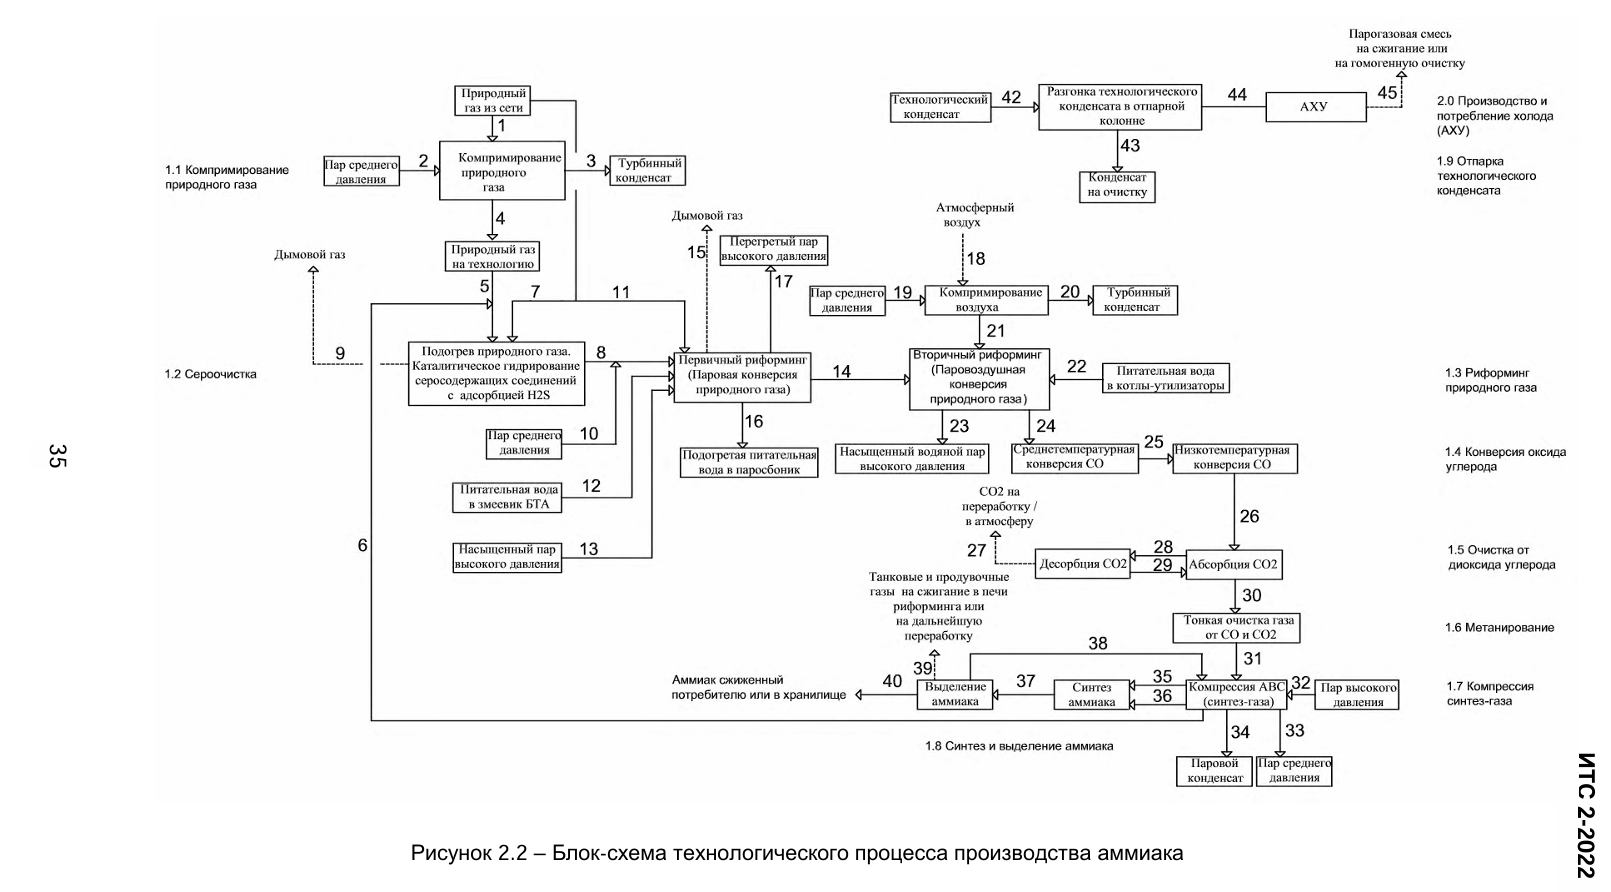


| Номер процесса | Входной поток | Наименование подпроцесса | Выходной поток | Основное технологическое оборудование | Эмиссии |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **1.1 Компримирование природного газа** | Природный газ из сети (1)<br>Пар среднего давления (2) | Компрессия природного газа | Природный газ (4)<br>Паровой конденсат (3) | Компрессор природного газа, межступенчатое оборудование | — |
| **1.2 Сероочистка** | Природный газ на технологию (5)<br>Азото-водородная смесь (6)<br>Природный газ (топливо) (7) | Подогрев природного газа, каталитическое гидрирование серосодержащих соединений с адсорбцией H₂S | Природный газ, очищенный от серосодержащих соединений (газовая смесь) (8)<br>Дымовой газ (9) | Аппарат гидрирования, аппарат сероочистки, огневой подогреватель | Дымовые газы из огневого подогревателя в атмосферу (NOₓ, CO) |
| **1.3 Риформинг природного газа** | Газовая смесь (8)<br>Пар среднего давления (10)<br>Природный газ (топливо) (11)<br>Питательная вода в змеевик БТА (12)<br>Насыщенный пар высокого давления (13) | Паровая конверсия природного газа | Конвертированный газ (14)<br>Дымовой газ (15)<br>Подогретая питательная вода в паросборник (16)<br>Перегретый пар высокого давления (17) | Трубчатая печь с блоком теплоиспользующей аппаратуры (БТА), паросборник, котлы-утилизаторы, шахтный конвертер метана | Дымовой газ в атмосферу (NOₓ, CO) |
| **1.3 Риформинг природного газа** | Конвертированный газ (14)<br>Сжатый воздух (21)<br>Питательная вода в котлы-утилизаторы (22) | Паровоздушная конверсия природного газа | Конвертированный газ (24)<br>Насыщенный водяной пар высокого давления (23) | Трубчатая печь с блоком теплоиспользующей аппаратуры (БТА), паросборник, котлы-утилизаторы, шахтный конвертер метана | — |
| **1.3 Риформинг природного газа** | Атмосферный воздух (18)<br>Пар среднего давления (19) | Компрессия воздуха | Сжатый воздух (21)<br>Паровой конденсат (20) | Компрессор воздуха, межступенчатое оборудование | — |
| **1.4 Конверсия монооксида углерода** | Конвертированный газ (24) | Среднетемпературная конверсия CO | Конвертированный газ (25) | Среднетемпературный конвертер | — |
| **1.4 Конверсия монооксида углерода** | Конвертированный газ (25) | Низкотемпературная конверсия CO | Конвертированный газ (26) | Низкотемпературный конвертер | — |
| **1.5 Очистка от диоксида углерода** | Конвертированный газ (26)<br>Регенерированный раствор (МЭА, МДЭА, поташ) (29) | Абсорбция CO₂ | Конвертированный газ (30)<br>Раствор на регенерацию (28) | Абсобер, регенератор | Фракция CO₂ в атмосферу или на переработку |
| **1.5 Очистка от диоксида углерода** | Раствор на регенерацию (28) | Десорбция CO₂ | Регенерированный раствор (МЭА, МДЭА, поташ) (19)<br>CO₂ на переработку (27) | Абсобер, регенератор | Фракция CO₂ в атмосферу или на переработку |
| **1.6 Метанирование** | Конвертированный газ (30) | Тонкая очистка газа от CO и CO₂ (метанирование или КЦА) | АВС (синтез-газ) (31) | Метанатор | — |
| **1.7 Компрессия синтез-газа** | АВС (синтез-газ) (31)<br>Пар высокого давления (32)<br>Циркуляционный газ (38) | Компрессия АВС (синтез-газа) | АВС (синтез-газ) (35)<br>Пар среднего давления (33)<br>Циркуляционный газ (36)<br>Азото-водородная смесь (6) на стадию сероочистки<br>Паровой конденсат (34) | Компрессор синтез-газа, межступенчатое оборудование | — |
| **1.8 Синтез и выделение аммиака** | АВС (синтез-газ) (35)<br>Циркуляционный газ (36)<br>Холод, вырабатываемый в аммиачных холодильных установках или с помощью аммиачного компрессора (замкнутый цикл) | Синтез аммиака. Выделение аммиака | Циркуляционный газ (37)<br>Аммиак сжиженный (40)<br>Танковые и продувочные газы на сжигание в печи риформинга или на дальнейшую переработку (получение аргона и т. п.) (39)<br>Циркуляционный газ на компрессию АВС (синтез-газа) (38) | Колонна синтеза аммиака, теплообменное, сепарационное оборудование | — |
| **1.9 Отпарка технологического конденсата** | Технологический конденсат (42) | Разгонка технологического конденсата в отпарной колонне | Конденсат на очистку (43)<br>Парогазовая смесь (ПГС) (44) | Отпарная колонна, теплообменное оборудование | — |
| **2.0 АХУ** | ПГС (44) | Производство и потребление холода (АХУ) | На сжигание или на гомогенную очистку (45) | Генераторы-ректификаторы | — |






![alt text](mermaid-diagram-2026-10-18-134206.png)

2. Расход природного газа для установок АМ-76

По данным официального справочника ИТС 2-2022, норма расхода природного газа для агрегата АМ-76 составляет:
до 1275 нм³/т (норма с учетом всех стационарных источников).
1130 нм³/т (общее потребление по данным НИИК).
В пересчете на энергетические единицы это составляет 9,74–10,01 Гкал/т аммиака.

3. Другие реагенты

Помимо газа, на производство аммиака затрачивается:
Электроэнергия: < 159 кВт·ч/т.
Вода (подпиточная): 0,43–3,65 м³/т (в зависимости от технологии).
Азот: 20–38 нм³/т (подается с воздухом во вторичный риформинг).


4. Лимитирующий фактор реакции синтеза

Чаще всего реакцию ограничивает диссоциация (разрыв) молекулы азота (N₂) на поверхности катализатора.
Причина: Молекула N₂ имеет очень прочную тройную связь. Ее разрыв является самым медленным (лимитирующим) этапом всего процесса.
Следствие: Для ускорения этого этапа требуется высокая температура (380–450 °C) и огромное давление (до 300 атм), а также применение специальных промотированных катализаторов (Fe, Ru).


5. Примеры заводов в разных странах

CHAMBAL (Индия): Самый энергоэффективный завод в мире. Расход — 6,27 Гкал/т (около 24,9 MMBtu/т).

> **⚠ ИСПРАВЛЕНИЕ №1.** Было: «около 22,6 MMBtu/т». Стало: «около 24,9 MMBtu/т». Почему: 1 Гкал = 3,968 MMBtu (тот же множитель стоит в коде выше), 6,27 × 3,968 = 24,88. Значение 22,6 MMBtu соответствовало бы 5,7 Гкал/т.

EUROCHEM (Россия): Крупнейший в мире завод с одним реактором, мощностью более 3000 т/сутки.

YARA (Нидерланды): Самый надежный завод, проработавший 2162 дня подряд без остановок.


По официальному справочнику ИТС 2-2022, на производство одной тонны аммиака требуется 0.97 тонны природного газа (в пересчете через плотность). С учетом того, что для тонны карбамида нужно 577 кг аммиака плюс технологический пар, итоговый расход на тонну карбамида составляет около 0.64 тонны природного газа